<a href="https://colab.research.google.com/github/Ashwini9713/fundamentals-of-ML/blob/main/exp5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# K-Nearest Neighbours (K-NN) Implementation
This notebook demonstrates the implementation of the K-Nearest Neighbours (K-NN) classification algorithm using Python and `scikit-learn`.

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns

## 1. Create a Synthetic Dataset
We will generate a 2D dataset with 2 classes to make visualization easier.

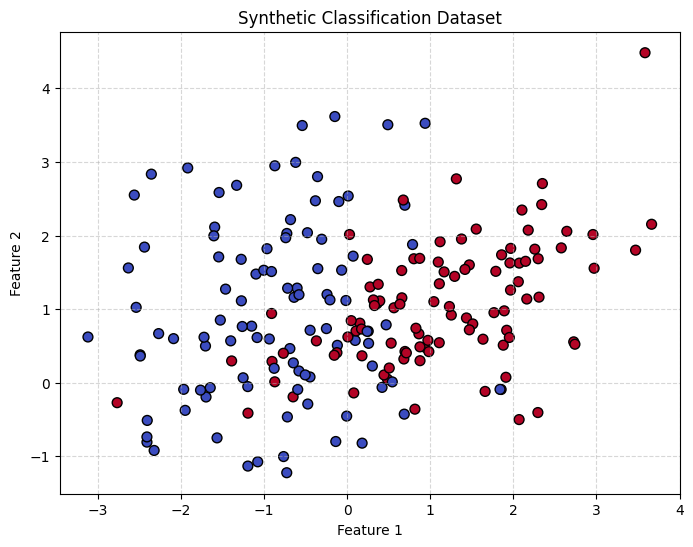

In [7]:
# Generate synthetic dataset
X, y = make_classification(n_samples=200, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, random_state=42)

# Visualize the generated dataset
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', edgecolors='k', s=50)
plt.title("Synthetic Classification Dataset")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 2. Split and Scale the Data
We split the dataset into training and testing sets, then standardize our features since distance metrics are highly sensitive to scales.

In [8]:
# Split into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## 3. Train the K-NN Classifier
We initialize the `KNeighborsClassifier` with a chosen $k$ (e.g., $k=5$) and fit it to our training data.

In [9]:
# Initialize K-NN Classifier with k=5
k = 5
knn = KNeighborsClassifier(n_neighbors=k)

# Train the model
knn.fit(X_train, y_train)

KNeighborsClassifier()

## 4. Evaluate the Model
We make predictions on the test set and analyze performance using accuracy metrics and a confusion matrix.

In [10]:
# Predict on test data
y_pred = knn.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

# Print classification report
print("Classification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 95.00%

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.91      0.95        23
           1       0.89      1.00      0.94        17

    accuracy                           0.95        40
   macro avg       0.95      0.96      0.95        40
weighted avg       0.96      0.95      0.95        40



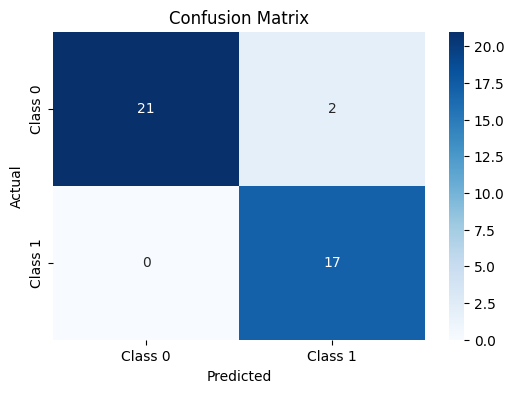

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Class 0', 'Class 1'],
            yticklabels=['Class 0', 'Class 1'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()